# Scoring du risque de crédit — German Credit Dataset (UCI)

**Auteur :** RAHHAL Fatima Zahrae · [GitHub](https://github.com/rahhalfatimazahrae) · [LinkedIn](https://www.linkedin.com/in/fatima-zahrae-rahhal-88b459300/)

---

**Objectif :** prédire si un demandeur de prêt est un *bon* ou un *mauvais* risque de crédit, et choisir une règle de décision qui minimise le **coût métier** des erreurs.

**Données :** UCI *Statlog (German Credit Data)* — 1 000 demandeurs, 20 variables (7 numériques, 13 catégorielles), 30 % de mauvais risques.

**Résultat clé :** l'ajustement du seuil de décision à la matrice de coût 5:1 (seuil 0,33) a réduit le coût sur le test de **150 à 94 (−37 %)** et fait passer la part de mauvais clients détectés de **58 % à 90 %**.

**Sommaire**
1. Configuration et chargement des données
2. Aperçu des données et contrôle qualité
3. Analyse exploratoire (EDA)
4. Prétraitement et découpage train/test
5. Comparaison de modèles (validation croisée)
6. Évaluation finale sur le jeu de test
7. Seuil de décision sensible au coût
8. Interprétabilité
9. Conclusions et limites

## 1. Configuration et chargement des données
Le fichier brut n'a pas d'en-tête et utilise des codes (`A11`, `A34`…). On ajoute les noms de colonnes et on décode les catégories en libellés lisibles.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")

# Works whether the notebook sits next to the data file or inside notebooks/ (repo layout)
from pathlib import Path
DATA_PATH = next(p for p in (Path("german.data"), Path("../data/german.data"), Path("data/german.data")) if p.exists())
import os; os.makedirs("images", exist_ok=True)
IMG = "images/"

In [2]:
columns = ["checking_account","duration","credit_history","purpose","credit_amount","savings",
           "employment","installment_rate","personal_status","other_debtors","residence_since","property",
           "age","other_installment_plans","housing","existing_credits","job","num_dependents",
           "telephone","foreign_worker","credit_risk"]

df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=columns)

# Décodage des codes catégoriels en libellés lisibles
decode = {'checking_account': {'A11': '< 0 DM', 'A12': '0-200 DM', 'A13': '≥ 200 DM / salaire', 'A14': 'pas de compte courant'}, 'credit_history': {'A30': 'aucun crédit / tout remboursé', 'A31': 'tout remboursé (cette banque)', 'A32': 'crédits en cours remboursés', 'A33': 'retard passé', 'A34': 'compte critique / autres crédits'}, 'purpose': {'A40': 'voiture (neuve)', 'A41': 'voiture (occasion)', 'A42': 'meubles', 'A43': 'radio/TV', 'A44': 'électroménager', 'A45': 'réparations', 'A46': 'éducation', 'A47': 'vacances', 'A48': 'reconversion', 'A49': 'entreprise', 'A410': 'autre'}, 'savings': {'A61': '< 100 DM', 'A62': '100-500 DM', 'A63': '500-1000 DM', 'A64': '≥ 1000 DM', 'A65': 'inconnu / aucune'}, 'employment': {'A71': 'sans emploi', 'A72': '< 1 an', 'A73': '1-4 ans', 'A74': '4-7 ans', 'A75': '≥ 7 ans'}, 'personal_status': {'A91': 'homme div./séparé', 'A92': 'femme div./séparée/mariée', 'A93': 'homme célibataire', 'A94': 'homme marié/veuf', 'A95': 'femme célibataire'}, 'other_debtors': {'A101': 'aucun', 'A102': 'co-demandeur', 'A103': 'garant'}, 'property': {'A121': 'immobilier', 'A122': 'épargne/assurance-vie', 'A123': 'voiture/autre', 'A124': 'inconnu / aucun'}, 'other_installment_plans': {'A141': 'banque', 'A142': 'magasins', 'A143': 'aucun'}, 'housing': {'A151': 'location', 'A152': 'propriétaire', 'A153': 'logé gratuitement'}, 'job': {'A171': 'sans emploi/non qualifié non-résident', 'A172': 'non qualifié résident', 'A173': 'qualifié', 'A174': 'cadre/très qualifié'}, 'telephone': {'A191': 'non', 'A192': 'oui'}, 'foreign_worker': {'A201': 'oui', 'A202': 'non'}}
for col, mapping in decode.items():
    df[col] = df[col].map(mapping)

# Cible : 1 = mauvais risque (classe positive), 0 = bon risque
df["credit_risk"] = df["credit_risk"].map({1: 0, 2: 1})

print(df.shape)
df.head()

(1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,< 0 DM,6,compte critique / autres crédits,radio/TV,1169,inconnu / aucune,≥ 7 ans,4,homme célibataire,aucun,...,immobilier,67,aucun,propriétaire,2,qualifié,1,oui,oui,0
1,0-200 DM,48,crédits en cours remboursés,radio/TV,5951,< 100 DM,1-4 ans,2,femme div./séparée/mariée,aucun,...,immobilier,22,aucun,propriétaire,1,qualifié,1,non,oui,1
2,pas de compte courant,12,compte critique / autres crédits,éducation,2096,< 100 DM,4-7 ans,2,homme célibataire,aucun,...,immobilier,49,aucun,propriétaire,1,non qualifié résident,2,non,oui,0
3,< 0 DM,42,crédits en cours remboursés,meubles,7882,< 100 DM,4-7 ans,2,homme célibataire,garant,...,épargne/assurance-vie,45,aucun,logé gratuitement,1,qualifié,2,non,oui,0
4,< 0 DM,24,retard passé,voiture (neuve),4870,< 100 DM,1-4 ans,3,homme célibataire,aucun,...,inconnu / aucun,53,aucun,logé gratuitement,2,qualifié,2,non,oui,1


## 2. Aperçu des données et contrôle qualité

In [3]:
print("Lignes / colonnes :", df.shape)
print("Valeurs manquantes :", int(df.isnull().sum().sum()))
print("Lignes dupliquées :", int(df.duplicated().sum()))
bad_rate = df["credit_risk"].mean()
print(f"Taux de mauvais risque : {bad_rate:.1%}  |  Taux de bon risque : {1-bad_rate:.1%}")
df.describe().T

Lignes / colonnes : (1000, 21)
Valeurs manquantes : 0
Lignes dupliquées : 0
Taux de mauvais risque : 30.0%  |  Taux de bon risque : 70.0%


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
credit_risk,1000.0,0.300,0.458487,0.0,0.0,0.0,1.00,1.0


Le jeu de données est propre (ni valeurs manquantes, ni doublons) mais **déséquilibré** : environ 30 % de mauvais risques. L'accuracy seule serait trompeuse — un modèle qui accepte tout le monde obtient déjà ~70 %.

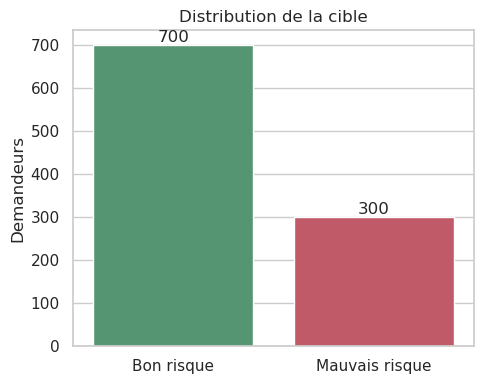

In [4]:
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x="credit_risk", ax=ax, palette=["#4C9F70","#D1495B"])
ax.set_xticklabels(["Bon risque","Mauvais risque"])
ax.set_xlabel(""); ax.set_ylabel("Demandeurs")
ax.set_title("Distribution de la cible")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(IMG+"01_target_fr.png", dpi=150); plt.show()

## 3. Analyse exploratoire (EDA)
### 3.1 Variables numériques vs risque

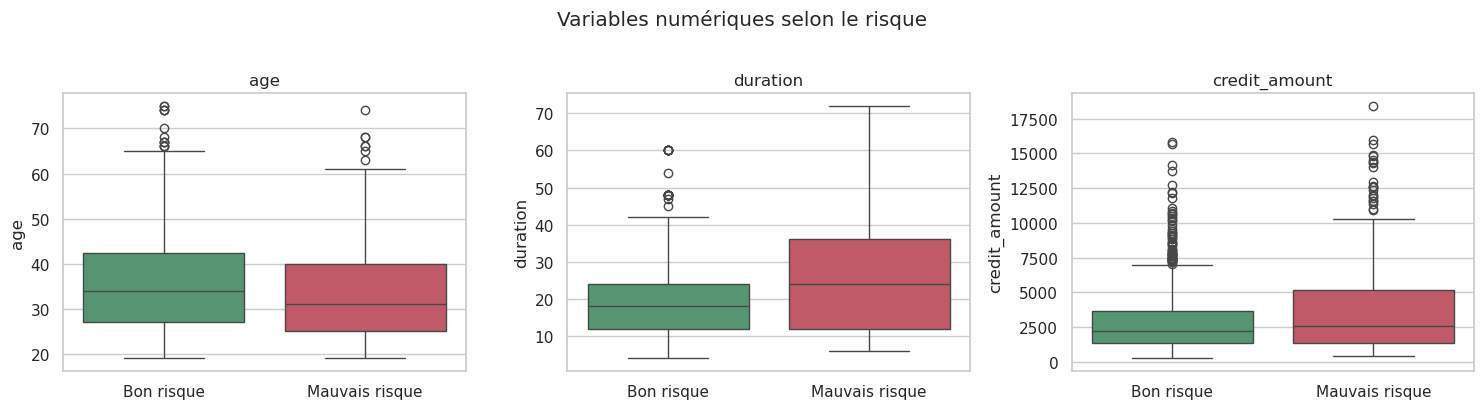

,age,duration,credit_amount
credit_risk,,,
0,34.0,18.0,2244.0
1,31.0,24.0,2574.5


In [5]:
num_cols = ["age","duration","credit_amount"]
labels = {0:"Bon risque", 1:"Mauvais risque"}
d = df.assign(risk=df["credit_risk"].map(labels))
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=d, x="risk", y=c, order=["Bon risque","Mauvais risque"], palette=["#4C9F70","#D1495B"], ax=ax)
    ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Variables numériques selon le risque", y=1.02); plt.tight_layout()
plt.savefig(IMG+"02_numeric_fr.png", dpi=150, bbox_inches="tight"); plt.show()
df.groupby("credit_risk")[num_cols].median()

Les mauvais risques demandent plutôt des **montants plus élevés sur des durées plus longues** et sont légèrement **plus jeunes**.

### 3.2 Variables catégorielles — taux de défaut par modalité

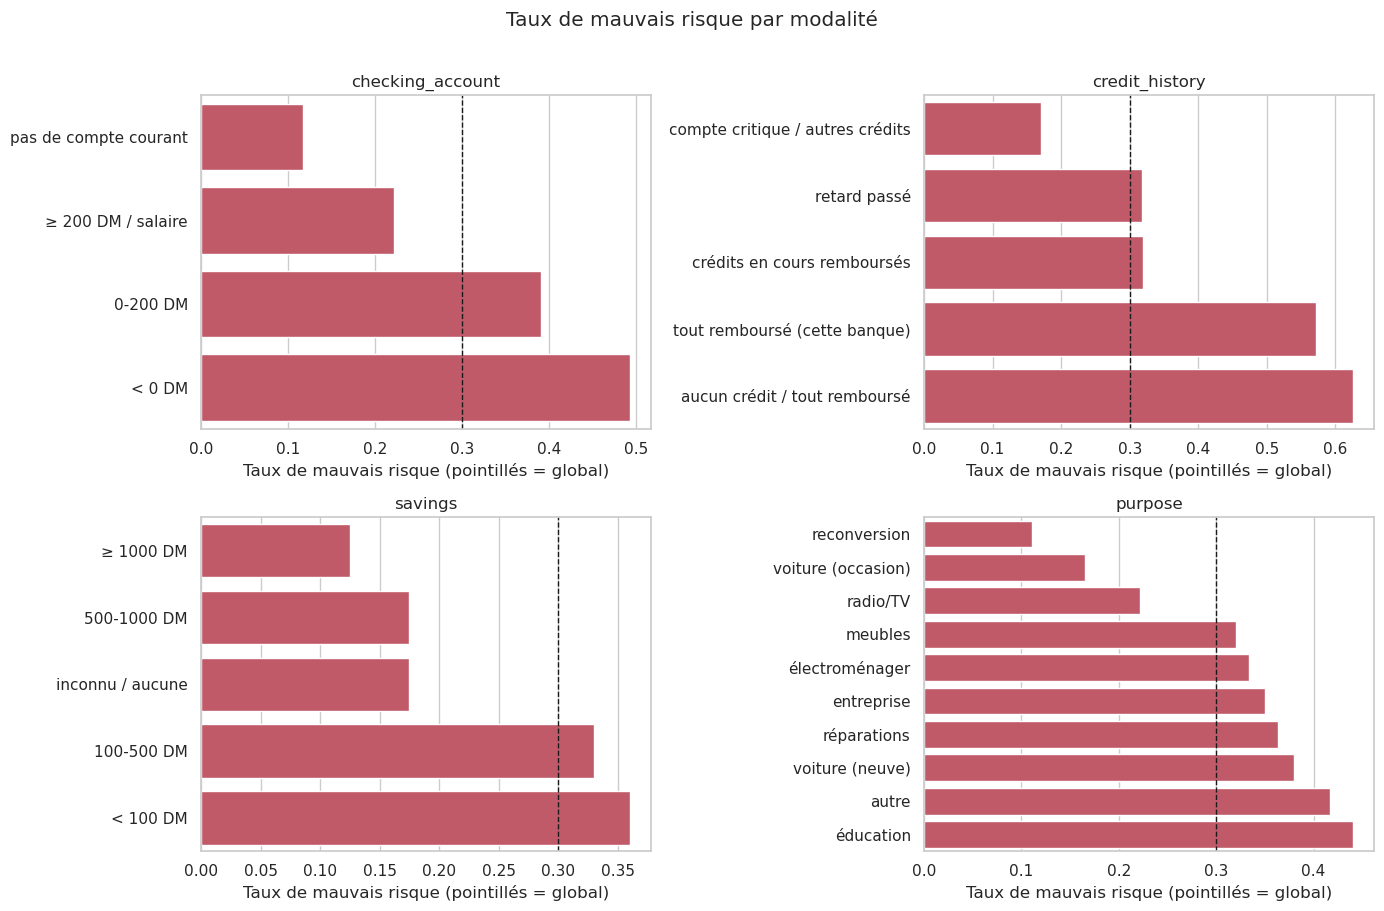

In [6]:
cats = ["checking_account","credit_history","savings","purpose"]
fig, axes = plt.subplots(2, 2, figsize=(14,9))
for ax, c in zip(axes.ravel(), cats):
    rate = df.groupby(c)["credit_risk"].mean().sort_values()
    sns.barplot(x=rate.values, y=rate.index, color="#D1495B", ax=ax)
    ax.axvline(df["credit_risk"].mean(), color="k", ls="--", lw=1)
    ax.set_xlabel("Taux de mauvais risque (pointillés = global)"); ax.set_ylabel(""); ax.set_title(c)
plt.suptitle("Taux de mauvais risque par modalité", y=1.01); plt.tight_layout()
plt.savefig(IMG+"03_categorical_fr.png", dpi=150, bbox_inches="tight"); plt.show()

Le **statut du compte courant** est le signal le plus fort : les demandeurs au solde négatif font défaut bien plus souvent que ceux sans compte courant. Une épargne faible augmente aussi le risque. De façon contre-intuitive, un historique de crédit *critique* présente le taux de défaut le **plus bas** (17 %) tandis que « aucun crédit / tout remboursé » présente le plus haut (57-62 %) : particularité connue de ce jeu de données (les clients à long historique bancaire sont probablement mieux sélectionnés), et non une règle causale.

### 3.3 Corrélations (variables numériques)

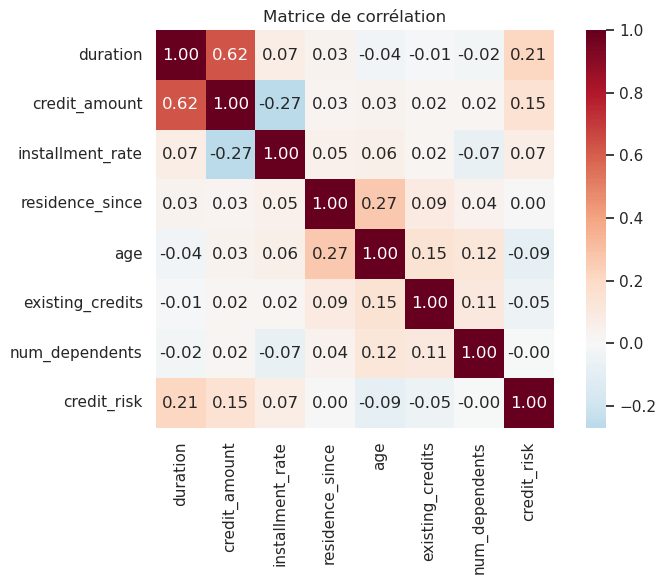

In [7]:
num_all = df.select_dtypes("number").columns
plt.figure(figsize=(8,6))
sns.heatmap(df[num_all].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Matrice de corrélation"); plt.tight_layout()
plt.savefig(IMG+"04_corr_fr.png", dpi=150); plt.show()

`duration` et `credit_amount` sont fortement corrélées (≈ 0,62), ce qui est logique : les gros prêts durent plus longtemps. Aucune paire n'est assez corrélée pour justifier de supprimer une variable.

## 4. Prétraitement et découpage train/test
Le découpage est **stratifié** afin de conserver le ratio 70/30 dans les deux jeux. Tout le prétraitement est dans un `Pipeline` : mise à l'échelle et encodage sont appris uniquement sur les plis d'entraînement (**pas de fuite de données**).

In [8]:
X = df.drop(columns="credit_risk"); y = df["credit_risk"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

num_features = X.select_dtypes("number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

# Fixed category order (original code order) -> identical results whatever the label language
cat_order = [list(decode[c].values()) for c in cat_features]
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(categories=cat_order, sparse_output=False), cat_features),
])
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Taux de mauvais risque train/test :", round(y_train.mean(),3), round(y_test.mean(),3))

Train: (800, 20) | Test: (200, 20)
Taux de mauvais risque train/test : 0.3 0.3


## 5. Comparaison de modèles (validation croisée stratifiée à 5 plis)
On compare quatre modèles sur le **jeu d'entraînement uniquement**. Métriques : **ROC-AUC** (qualité du classement), **PR-AUC** (robuste au déséquilibre) et **Rappel des mauvais risques** (part des défaillants détectés).

In [9]:
models = {
    "Logistic Regression":            LogisticRegression(max_iter=2000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest (balanced)":       RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=1),
    "Gradient Boosting":              HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED),
}
pipes = {n: Pipeline([("prep", preprocessor), ("clf", m)]) for n, m in models.items()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc":"roc_auc", "pr_auc":"average_precision", "recall_bad":"recall"}

rows = []
for name, pipe in pipes.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name,
                 "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC (std)": r["test_roc_auc"].std(),
                 "PR-AUC": r["test_pr_auc"].mean(), "Recall (bad)": r["test_recall_bad"].mean()})
cv_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("ROC-AUC", ascending=False)
cv_results

,ROC-AUC,ROC-AUC (std),PR-AUC,Recall (bad)
model,,,,
Random Forest (balanced),0.797,0.043,0.634,0.562
Gradient Boosting,0.789,0.044,0.606,0.446
Logistic Regression,0.771,0.053,0.594,0.433
Logistic Regression (balanced),0.769,0.053,0.589,0.671


In [10]:
best_name = cv_results.index[0]
print("Meilleur modèle (ROC-AUC en CV) :", best_name)

Meilleur modèle (ROC-AUC en CV) : Random Forest (balanced)


## 6. Évaluation finale sur le jeu de test
Chaque modèle est ré-entraîné sur tout le jeu d'entraînement puis évalué **une seule fois** sur le jeu de test intact (seuil par défaut 0,5).

In [11]:
fitted, proba, rows = {}, {}, []
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train); fitted[name] = pipe
    p = pipe.predict_proba(X_test)[:,1]; proba[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                 "Recall (bad)": recall_score(y_test, pred), "Precision (bad)": precision_score(y_test, pred)})
test_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("ROC-AUC", ascending=False)
test_results

,ROC-AUC,PR-AUC,Recall (bad),Precision (bad)
model,,,,
Logistic Regression (balanced),0.806,0.633,0.800,0.558
Logistic Regression,0.804,0.635,0.533,0.667
Random Forest (balanced),0.803,0.653,0.583,0.583
Gradient Boosting,0.784,0.623,0.483,0.604


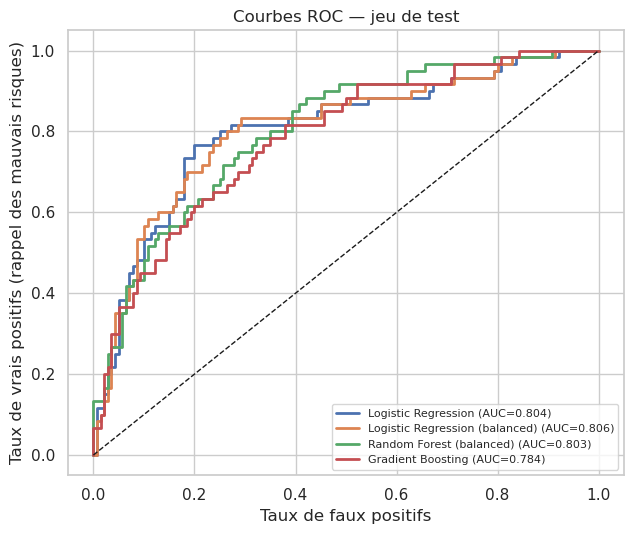

In [12]:
plt.figure(figsize=(6.5,5.5))
for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
plt.plot([0,1],[0,1],"k--", lw=1)
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs (rappel des mauvais risques)"); plt.title("Courbes ROC — jeu de test")
plt.legend(loc="lower right", fontsize=8); plt.tight_layout()
plt.savefig(IMG+"05_roc_fr.png", dpi=150); plt.show()

## 7. Seuil de décision sensible au coût
Dans la documentation du jeu de données d'origine, la **matrice de coût est asymétrique** :

| | Prédit bon | Prédit mauvais |
|---|---|---|
| **Réellement bon** | 0 | 1 (manque à gagner) |
| **Réellement mauvais** | **5** (perte sur défaut) | 0 |

Accepter un défaillant coûte **5 fois** plus cher que refuser un bon client : le seuil par défaut de 0,5 n'est donc pas optimal. Si les probabilités étaient parfaitement calibrées, la règle optimale serait de classer un demandeur « mauvais » dès que p > 1/(1+5) ≈ **0,17**.

Pour éviter toute fuite du jeu de test, le seuil est **choisi sur les prédictions out-of-fold du jeu d'entraînement**, puis appliqué une seule fois au test.

In [13]:
COST_FN, COST_FP = 5, 1   # FN: bad client approved | FP: good client rejected

def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return COST_FN*fn + COST_FP*fp

best_pipe = pipes[best_name]
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:,1]

thresholds = np.linspace(0.05, 0.95, 91)
oof_costs = [total_cost(y_train, (oof >= th).astype(int)) for th in thresholds]
best_th = float(thresholds[int(np.argmin(oof_costs))])
print("Seuil sélectionné sur les prédictions OOF du train :", round(best_th, 2))

Seuil sélectionné sur les prédictions OOF du train : 0.33


In [14]:
p_test = proba[best_name]
strategies = {
    "Tout accepter": np.zeros(len(y_test), dtype=int),
    "Tout refuser": np.ones(len(y_test), dtype=int),
    "Modèle @ seuil 0,5": (p_test >= 0.5).astype(int),
    f"Modèle @ seuil optimisé ({best_th:.2f})": (p_test >= best_th).astype(int),
}
res = []
for k, pred in strategies.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    res.append({"stratégie": k, "coût total": COST_FN*fn + COST_FP*fp, "Recall (bad)": round(tp/(tp+fn),3),
                "Taux de faux positifs": round(fp/(fp+tn),3)})
cost_table = pd.DataFrame(res).set_index("stratégie")
cost_table

,coût total,Recall (bad),Taux de faux positifs
stratégie,,,
Tout accepter,300,0.000,0.000
Tout refuser,140,1.000,1.000
"Modèle @ seuil 0,5",150,0.583,0.179
Modèle @ seuil optimisé (0.33),94,0.900,0.457


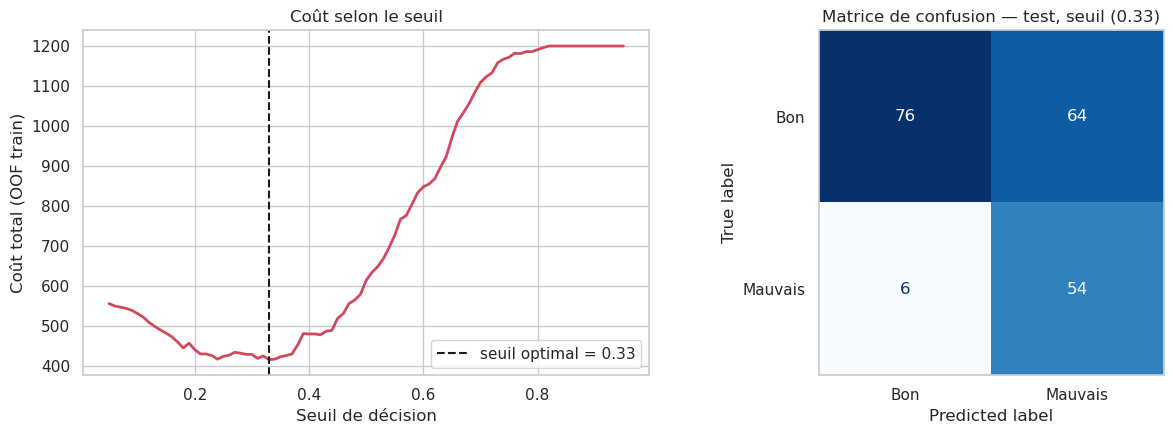

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].plot(thresholds, oof_costs, color="#D1495B", lw=2)
axes[0].axvline(best_th, color="k", ls="--", label=f"seuil optimal = {best_th:.2f}")
axes[0].set_xlabel("Seuil de décision"); axes[0].set_ylabel("Coût total (OOF train)"); axes[0].set_title("Coût selon le seuil"); axes[0].legend()

ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= best_th).astype(int), ax=axes[1],
    display_labels=["Bon","Mauvais"], cmap="Blues", colorbar=False)
axes[1].set_title("Matrice de confusion — test, seuil " + f"({best_th:.2f})"); axes[1].grid(False)
plt.tight_layout(); plt.savefig(IMG+"06_threshold_fr.png", dpi=150); plt.show()

## 8. Interprétabilité
### 8.1 Odds ratios de la régression logistique
Un odds ratio > 1 signifie que la variable **augmente** les chances d'être un mauvais risque. Les variables numériques sont standardisées : leur odds ratio correspond à **+1 écart-type**.

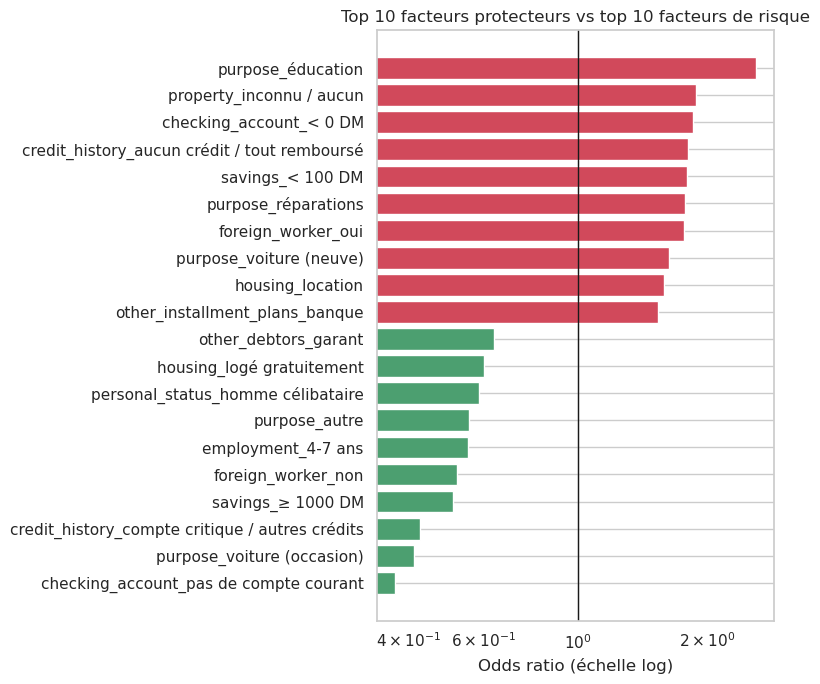

In [16]:
lr = pipes["Logistic Regression (balanced)"]
names = lr.named_steps["prep"].get_feature_names_out()
or_ = pd.Series(np.exp(lr.named_steps["clf"].coef_[0]), index=names).sort_values()
or_.index = [i.replace("num__","").replace("cat__","") for i in or_.index]
top = pd.concat([or_.head(10), or_.tail(10)])

plt.figure(figsize=(8,7))
colors = ["#4C9F70" if v < 1 else "#D1495B" for v in top.values]
plt.barh(top.index, top.values, color=colors); plt.axvline(1, color="k", lw=1)
plt.xscale("log"); plt.xlabel("Odds ratio (échelle log)"); plt.title("Top 10 facteurs protecteurs vs top 10 facteurs de risque")
plt.tight_layout(); plt.savefig(IMG+"07_odds_fr.png", dpi=150); plt.show()

### 8.2 Importance par permutation (meilleur modèle, jeu de test)
Indépendante du modèle : de combien le ROC-AUC chute-t-il quand on mélange une variable d'origine ?

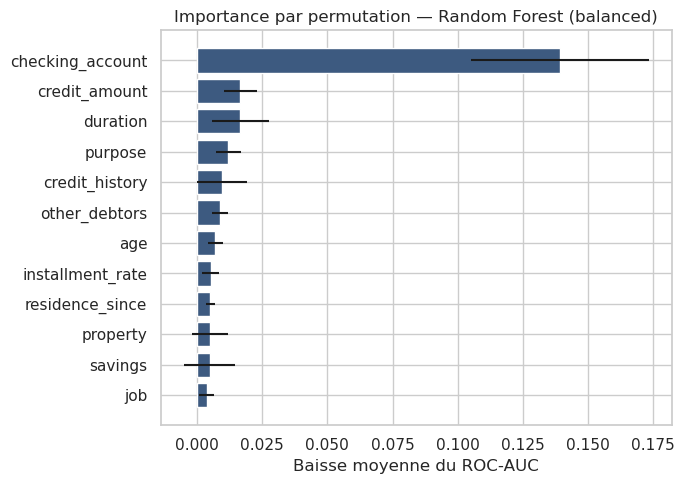

In [17]:
pi = permutation_importance(fitted[best_name], X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(12)
err = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]

plt.figure(figsize=(7,5))
plt.barh(imp.index, imp.values, xerr=err.values, color="#3D5A80")
plt.xlabel("Baisse moyenne du ROC-AUC"); plt.title("Importance par permutation — " + best_name)
plt.tight_layout(); plt.savefig(IMG+"08_perm_fr.png", dpi=150); plt.show()

## 9. Conclusions et limites

**Résultats**
- **Qualité des modèles :** les quatre modèles atteignent un ROC-AUC proche, d'environ **0,77–0,81** (validation croisée : Random Forest 0,797, Régression logistique 0,771 ; test : 0,78–0,81). Les écarts sont dans l'écart-type de la CV (≈ 0,04) : aucun modèle n'est nettement meilleur — une **régression logistique** simple et explicable est tout à fait compétitive.
- **Valeur métier :** avec la matrice de coût 5:1, passer le seuil de 0,50 à **0,33** réduit le coût sur le test de **150 à 94 (−37 %)**, et le rappel des mauvais risques passe de **0,58 à 0,90**. À titre de référence, tout accepter coûte 300 et tout refuser coûte 140.
- **Compromis :** le prix à payer est davantage de fausses alertes — le modèle refuse environ **46 % des bons clients** (contre 18 % à 0,50). Le bon seuil reste in fine une décision métier.
- **Pourquoi 0,33 et pas 0,17 ?** Le seuil théorique 1/6 suppose des probabilités calibrées. Une Random Forest avec `class_weight="balanced"` n'est pas calibrée, d'où un optimum empirique différent.
- **Principaux facteurs :** le statut du compte courant domine nettement (importance par permutation très supérieure aux autres), suivi de la durée, du montant, de l'objet du prêt et de l'historique de crédit.

**Limites**
- Seulement **1 000 lignes** (200 dans le test, 60 mauvais clients) : les métriques de test sont bruitées et à lire comme indicatives. Le même code a donné un coût de 150 → 94 dans un environnement et 128 → 100 dans un autre (versions de bibliothèques différentes) : il faut donc rester prudent face aux petits écarts.
- Le jeu de données date de 1994 (Allemagne, en DM) et comporte des particularités (ex. le paradoxe de l'historique de crédit *critique* vu dans l'EDA).
- **Équité :** `personal_status`, `foreign_worker` et `age` sont des attributs sensibles. Un modèle de scoring en production ne pourrait pas les utiliser légalement dans de nombreuses juridictions ; ils sont conservés ici uniquement pour rester comparable au benchmark d'origine, à titre d'exercice pédagogique.

**Pistes d'amélioration :** validation croisée répétée/imbriquée, réglage des hyperparamètres, calibration des probabilités, explications SHAP, audit d'équité (avec et sans variables sensibles) et une petite démo Streamlit.
